# devbrain (E7-E10) + Brooks 2025 (E7.5-E8.75) joint integration

**Why.** In the devbrain-only graph, e7.0 shares 0.0% of its kNN neighbours with e9.0/e10.0
and 95% of its cells sit in a neighbourhood that is >90% e7.0. No pseudotime or RNA-velocity
method can traverse that gap, so the early trajectory is unreachable.

**Idea (yubin).** Brooks 2025 (GSE273804, FVB wild-type timeseries) densely samples the window
that devbrain skips - E7.5, E7.75, E8.0, E8.25, E8.5, E8.75 - so it can act as a bridge.
The combined timeline interleaves, with genuine overlap at E8.0 and E8.5:

| 7.0 | 7.5 | 7.75 | 8.0 | 8.25 | 8.5 | 8.75 | 9.0 | 10.0 |
|-----|-----|------|-----|------|-----|------|-----|------|
| devbrain | Brooks | Brooks | both | Brooks | both | Brooks | devbrain | devbrain |

Those shared stages are the test: if correction worked, the two datasets should overlap
*there* specifically, not everywhere uniformly.

**Batch key.** Harmony is run on `dataset` (2 levels), not on sample/replicate. Within each
dataset the sample labels are nested inside stage (every devbrain library is one timepoint;
every Brooks replicate is one stage), so correcting on them would remove the developmental
signal this whole exercise is meant to recover. The dominant batch effect here is
cross-platform anyway: devbrain is 2016 10x v1 (14 bp barcodes, ~3.1k genes/cell) and Brooks
is modern chemistry (~5.8k genes/cell).

In [1]:
import os

import anndata as ad
import h5py
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.sparse import csr_matrix

sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, dpi_save=200, frameon=False, figsize=(5, 5))

EXPR_CMAP = LinearSegmentedColormap.from_list(
    "expr", ["#FCC9B4", "#FB8A6A", "#E32F27", "#99000D"]
)
BG_GREY = "#DDDDDD"

In [2]:
base = "/project/imoskowitz/yubin/Trajectory_inference/"
devbrain_h5 = base + "data/interim/devbrain_E7-E10_processed.h5ad"
brooks_h5 = ("/project/imoskowitz/kdreyer/public_datasets/"
             "001_Brooks2025_GSE273804/WT_timeseries/GSE273804_FVB_All.h5ad")

fig_int = base + "results/figures/06_integration_brooks/"
os.makedirs(fig_int, exist_ok=True)
sc.settings.figdir = fig_int

## Load

Both are read straight from HDF5 rather than with `sc.read_h5ad`: the Brooks file is 7.4 GB
because it stores `X`, `raw`, `norm_counts` and `raw_counts` - four copies of the same
227M-nonzero matrix. We only need the raw counts.

In [3]:
def read_counts(path, counts_key, obs_cols):
    """Pull one count matrix plus selected obs columns out of an h5ad."""
    with h5py.File(path, "r") as f:
        g = f[counts_key]
        X = csr_matrix((g["data"][:], g["indices"][:], g["indptr"][:]),
                       shape=tuple(f["X"].attrs["shape"]))
        var_names = f["var/_index"].asstr()[:]
        obs_names = f["obs/_index"].asstr()[:]

        def dec(col):
            o = f["obs"][col]
            if isinstance(o, h5py.Group):           # categorical
                cats = o["categories"].asstr()[:]
                codes = o["codes"][:]
                return np.where(codes >= 0, cats[np.clip(codes, 0, None)], "")
            return o.asstr()[:] if o.dtype.kind in "OS" else o[:]

        obs = pd.DataFrame({c: dec(c) for c in obs_cols}, index=pd.Index(obs_names))
    a = ad.AnnData(X=X, obs=obs, var=pd.DataFrame(index=pd.Index(var_names)))
    a.X = a.X.astype(np.float32)
    return a


dev = read_counts(devbrain_h5, "layers/counts",
                  ["sample", "age", "tissue", "leiden"])
dev.obs["dataset"] = "devbrain"
dev.obs["stage"] = dev.obs["age"].str.replace("e", "E", regex=False)
dev.obs["chip"] = dev.obs["sample"].str.split("_").str[0]
dev.obs["batch_fine"] = "devbrain:" + dev.obs["chip"]
dev.obs["celltype_src"] = "unannotated"
print(dev)

AnnData object with n_obs × n_vars = 68166 × 21743
    obs: 'sample', 'age', 'tissue', 'leiden', 'dataset', 'stage', 'chip', 'batch_fine', 'celltype_src'


In [4]:
brooks = read_counts(brooks_h5, "layers/raw_counts",
                     ["Sample ID", "stage", "Batch", "Cell Type",
                      "Neural Plate Annotation", "background_cell"])
brooks.obs["dataset"] = "brooks"
brooks.obs["batch_fine"] = "brooks:" + brooks.obs["Batch"].astype(str)
brooks.obs["celltype_src"] = brooks.obs["Cell Type"].astype(str)
brooks.obs["sample"] = brooks.obs["Sample ID"].astype(str)
print(brooks)
print("\nbackground_cell:", brooks.obs["background_cell"].value_counts().to_dict())

AnnData object with n_obs × n_vars = 39463 × 23063
    obs: 'Sample ID', 'stage', 'Batch', 'Cell Type', 'Neural Plate Annotation', 'background_cell', 'dataset', 'batch_fine', 'celltype_src', 'sample'

background_cell: {'True': 39463}


In [5]:
# `background_cell` in this file is a single-level categorical - 'True' for all
# 39,463 cells - so it does NOT mark barcodes to drop; every cell present has
# already passed the authors' background removal. Filtering on it would delete
# the whole dataset, so only act if the column actually has a False level.
bg_vals = set(brooks.obs["background_cell"].astype(str).str.lower())
print("background_cell levels:", bg_vals)
if {"false", "0"} & bg_vals:
    bg = brooks.obs["background_cell"].astype(str).str.lower().isin(["true", "1"])
    print(f"dropping {int(bg.sum())} flagged background barcodes")
    brooks = brooks[~bg.values].copy()
else:
    print("uninformative column - keeping all cells")
assert brooks.n_obs > 0, "all Brooks cells were filtered out"

STAGE_NUM = {"E7.0": 7.0, "E7.5": 7.5, "E7.75": 7.75, "E8.0": 8.0,
             "E8.25": 8.25, "E8.5": 8.5, "E8.75": 8.75, "E9.0": 9.0, "E10.0": 10.0}
for a in (dev, brooks):
    a.obs["stage"] = a.obs["stage"].astype(str)
    a.obs["stage_num"] = a.obs["stage"].map(STAGE_NUM).astype(float)
assert not dev.obs["stage_num"].isna().any() and not brooks.obs["stage_num"].isna().any()
print(pd.crosstab(pd.concat([dev.obs["stage"], brooks.obs["stage"]]),
                  pd.concat([dev.obs["dataset"], brooks.obs["dataset"]])))

background_cell levels: {'true'}
uninformative column - keeping all cells
dataset  brooks  devbrain
stage                    
E10.0         0     32136
E7.0          0     11195
E7.5       9533         0
E7.75      7101         0
E8.0       3444      6813
E8.25      3397         0
E8.5      10085      3241
E8.75      5903         0
E9.0          0     14781


## Shared gene space and concatenation

In [6]:
shared = sorted(set(dev.var_names) & set(brooks.var_names))
print(f"devbrain {dev.n_vars}, brooks {brooks.n_vars}, shared {len(shared)}")

dev = dev[:, shared].copy()
brooks = brooks[:, shared].copy()

comb = ad.concat(
    {"devbrain": dev, "brooks": brooks}, label="dataset_key", index_unique="-",
    join="outer", merge="first",
)
comb.obs["dataset"] = comb.obs["dataset"].astype("category")
comb.obs["stage"] = pd.Categorical(
    comb.obs["stage"], categories=[s for s in STAGE_NUM if s in set(comb.obs["stage"])],
    ordered=True,
)
comb.obs["batch_fine"] = comb.obs["batch_fine"].astype("category")
comb.obs["celltype_src"] = comb.obs["celltype_src"].astype("category")
comb.layers["counts"] = comb.X.copy()
del dev, brooks
assert set(comb.obs["dataset"].cat.categories) == {"devbrain", "brooks"}, \
    f'both datasets must survive concat, got {list(comb.obs["dataset"].cat.categories)}'
print(comb)
print(comb.obs.groupby(["dataset", "stage"], observed=True).size().to_string())

devbrain 21743, brooks 23063, shared 15200


AnnData object with n_obs × n_vars = 107629 × 15200
    obs: 'sample', 'age', 'tissue', 'leiden', 'dataset', 'stage', 'chip', 'batch_fine', 'celltype_src', 'stage_num', 'Sample ID', 'Batch', 'Cell Type', 'Neural Plate Annotation', 'background_cell', 'dataset_key'
    layers: 'counts'
dataset   stage
brooks    E7.5      9533
          E7.75     7101
          E8.0      3444
          E8.25     3397
          E8.5     10085
          E8.75     5903
devbrain  E7.0     11195
          E8.0      6813
          E8.5      3241
          E9.0     14781
          E10.0    32136


## Normalize, HVG, PCA

HVGs are selected with `batch_key="dataset"` here - unlike the within-devbrain run, this key
is *not* nested in stage (both datasets span multiple stages), so it selects genes that are
variable in both platforms rather than genes that merely separate them.

In [7]:
sc.pp.normalize_total(comb, target_sum=1e4)
sc.pp.log1p(comb)

sc.pp.highly_variable_genes(comb, n_top_genes=3000, flavor="seurat",
                            batch_key="dataset")
print(comb.var["highly_variable"].sum(), "HVGs")
print("HVG shared by both datasets:",
      int((comb.var["highly_variable_nbatches"] == 2).sum()))

normalizing counts per cell


    finished (0:00:03)


extracting highly variable genes


    finished (0:00:59)


3000 HVGs
HVG shared by both datasets: 1618


In [8]:
import gc

hvg = comb[:, comb.var["highly_variable"]].copy()
sc.pp.scale(hvg, max_value=10)
sc.tl.pca(hvg, n_comps=50, svd_solver="arpack")
comb.obsm["X_pca"] = hvg.obsm["X_pca"]
comb.uns["pca"] = hvg.uns["pca"]
del hvg
gc.collect()
print("X_pca:", comb.obsm["X_pca"].shape)

/home/yubin/.conda/envs/scRNAseq_python/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


computing PCA


    with n_comps=50


    finished (0:00:17)


X_pca: (107629, 50)


## Baseline: uncorrected graph

In [9]:
sc.pp.neighbors(comb, n_neighbors=15, n_pcs=30, key_added="pre")
sc.tl.umap(comb, min_dist=0.3, neighbors_key="pre")
comb.obsm["X_umap_pre"] = comb.obsm["X_umap"].copy()

computing neighbors


    using 'X_pca' with n_pcs = 30


/home/yubin/.conda/envs/scRNAseq_python/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished (0:00:42)


computing UMAP


    finished (0:02:02)


## Harmony on `dataset`

In [10]:
sc.external.pp.harmony_integrate(
    comb, "dataset", basis="X_pca", adjusted_basis="X_pca_harmony",
    max_iter_harmony=20,
)
sc.pp.neighbors(comb, n_neighbors=15, n_pcs=30, use_rep="X_pca_harmony",
                key_added="post")
sc.tl.umap(comb, min_dist=0.3, neighbors_key="post")
comb.obsm["X_umap_post"] = comb.obsm["X_umap"].copy()
sc.tl.leiden(comb, resolution=1.0, key_added="leiden_joint", flavor="igraph",
             n_iterations=2, neighbors_key="post")
print(f"{comb.obs['leiden_joint'].nunique()} joint clusters")

2026-10-29 14:20:48,645 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


2026-10-29 14:20:56,514 - harmonypy - INFO - sklearn.KMeans initialization complete.


2026-10-29 14:20:56,969 - harmonypy - INFO - Iteration 1 of 20


2026-10-29 14:21:35,420 - harmonypy - INFO - Iteration 2 of 20


2026-10-29 14:22:12,940 - harmonypy - INFO - Converged after 2 iterations


...

computing UMAP


    finished (0:02:01)


running Leiden clustering


    finished (0:00:05)


32 joint clusters


## Did the graph actually connect?

Three questions, in order of how easy they are to fool yourself about:

1. Do the two datasets mix at all? (necessary, not sufficient - uniform mixing would be a
   red flag, since these datasets genuinely differ in stage composition)
2. Do they mix **at the stages they share** (E8.0, E8.5) more than elsewhere?
3. Does devbrain e7.0 now have a path forward in time - neighbours at E7.5/E7.75 - where
   before it had none?

In [11]:
def mixing(adata, key, neighbors_key, verbose=True):
    """Mean share of each cell's kNN neighbours coming from each category."""
    A = (adata.obsp[f"{neighbors_key}_connectivities"] > 0).astype(np.float32)
    cats = list(adata.obs[key].cat.categories)
    onehot = np.zeros((adata.n_obs, len(cats)), dtype=np.float32)
    onehot[np.arange(adata.n_obs), adata.obs[key].cat.codes.values] = 1
    frac = A @ onehot
    frac = frac / np.maximum(frac.sum(1, keepdims=True), 1)
    mix = pd.DataFrame([frac[(adata.obs[key] == c).values].mean(0) for c in cats],
                       index=cats, columns=cats)
    if verbose:
        print((100 * mix).round(1).to_string())
    return mix, frac


print("--- dataset mixing BEFORE ---")
mix_ds_pre, frac_ds_pre = mixing(comb, "dataset", "pre")
print("\n--- dataset mixing AFTER ---")
mix_ds_post, frac_ds_post = mixing(comb, "dataset", "post")

--- dataset mixing BEFORE ---
             brooks   devbrain
brooks    99.599998   0.400000
devbrain   0.200000  99.800003

--- dataset mixing AFTER ---
             brooks   devbrain
brooks    80.300003  19.700001
devbrain  13.700000  86.300003


In [12]:
# cross-dataset neighbour share per stage: should peak at the shared stages
other = {"devbrain": "brooks", "brooks": "devbrain"}
ds_cats = list(comb.obs["dataset"].cat.categories)
rows = []
for stage in comb.obs["stage"].cat.categories:
    for ds in ds_cats:
        m = ((comb.obs["stage"] == stage) & (comb.obs["dataset"] == ds)).values
        if m.sum() == 0:
            continue
        j = ds_cats.index(other[ds])
        rows.append({"stage": stage, "dataset": ds, "n_cells": int(m.sum()),
                     "pct_nbrs_other_dataset_pre": 100 * frac_ds_pre[m][:, j].mean(),
                     "pct_nbrs_other_dataset_post": 100 * frac_ds_post[m][:, j].mean()})
cross = pd.DataFrame(rows)
print(cross.round(1).to_string(index=False))

stage  dataset  n_cells  pct_nbrs_other_dataset_pre  pct_nbrs_other_dataset_post
 E7.0 devbrain    11195                         0.1                         12.8
 E7.5   brooks     9533                         0.1                         12.7
E7.75   brooks     7101                         0.1                         10.6
 E8.0   brooks     3444                         0.7                         19.2
 E8.0 devbrain     6813                         1.9                         31.5
E8.25   brooks     3397                         0.9                         21.3
 E8.5   brooks    10085                         0.4                         23.3
 E8.5 devbrain     3241                         0.1                         29.9
E8.75   brooks     5903                         0.7                         35.4
 E9.0 devbrain    14781                         0.1                         14.3
E10.0 devbrain    32136                         0.0                          8.4


In [13]:
# the headline test: does e7.0 reach forward in time now?
mix_stage_pre, _ = mixing(comb, "stage", "pre", verbose=False)
mix_stage_post, _ = mixing(comb, "stage", "post", verbose=False)

print("devbrain-only baseline had e7.0 -> e9.0/e10.0 at 0.0%\n")
print("stage-to-stage neighbour share, AFTER integration (rows = cell's own stage):")
print((100 * mix_stage_post).round(1).to_string())
print("\nE7.0 row, before vs after:")
print(pd.DataFrame({"before": 100 * mix_stage_pre.loc["E7.0"],
                    "after": 100 * mix_stage_post.loc["E7.0"]}).round(2).to_string())

# is the stage graph connected as a chain? check each consecutive pair
stages = list(mix_stage_post.index)
print("\nconsecutive-stage neighbour share (after):")
for a, b in zip(stages, stages[1:]):
    print(f"  {a:6s} <-> {b:6s}  {100*mix_stage_post.loc[a, b]:5.2f}% / "
          f"{100*mix_stage_post.loc[b, a]:5.2f}%")

devbrain-only baseline had e7.0 -> e9.0/e10.0 at 0.0%

stage-to-stage neighbour share, AFTER integration (rows = cell's own stage):
            E7.0       E7.5      E7.75       E8.0      E8.25  E8.5      E8.75       E9.0      E10.0
E7.0   86.099998   8.800000   3.300000   1.500000   0.300000   0.0   0.000000   0.000000   0.000000
E7.5   10.000000  56.500000  27.100000   4.300000   1.400000   0.3   0.000000   0.100000   0.300000
E7.75   4.800000  34.200001  47.099998   9.500000   2.900000   0.7   0.100000   0.300000   0.400000
E8.0    2.000000   4.900000   8.500000  62.700001  11.000000   6.8   1.200000   1.800000   1.200000
E8.25   1.200000   4.700000   7.500000  29.500000  29.799999  18.0   3.800000   2.800000   2.700000
E8.5    0.000000   0.300000   0.500000   5.000000   5.000000  57.0  14.500000   9.900000   7.900000
E8.75   0.000000   0.100000   0.100000   1.800000   2.300000  30.5  34.900002  12.100000  18.200001
E9.0    0.000000   0.100000   0.200000   1.100000   0.700000   9.4  

  E7.0   <-> E7.5     8.75% / 10.00%
  E7.5   <-> E7.75   27.11% / 34.19%
  E7.75  <-> E8.0     9.52% /  8.46%
  E8.0   <-> E8.25   11.00% / 29.52%
  E8.25  <-> E8.5    18.02% /  4.97%
  E8.5   <-> E8.75   14.49% / 30.53%
  E8.75  <-> E9.0    12.06% /  5.65%
  E9.0   <-> E10.0   34.96% / 17.47%


In [14]:
# graph connectivity, directly: how many components, and do the stages share one?
from scipy.sparse.csgraph import connected_components
n_comp, labels = connected_components(comb.obsp["post_connectivities"], directed=False)
sizes = pd.Series(labels).value_counts()
print(f"{n_comp} connected components; largest holds "
      f"{100*sizes.iloc[0]/comb.n_obs:.1f}% of cells")
comb.obs["component"] = labels
big = sizes.index[0]
print("\nstages present in the largest component:")
print(comb.obs.loc[comb.obs["component"] == big, "stage"]
      .value_counts().sort_index().to_string())
leftover = comb.obs.loc[comb.obs["component"] != big]
if len(leftover):
    print(f"\n{len(leftover)} cells outside it, by stage/dataset:")
    print(leftover.groupby(["dataset", "stage"], observed=True).size().to_string())

1 connected components; largest holds 100.0% of cells

stages present in the largest component:
stage
E7.0     11195
E7.5      9533
E7.75     7101
E8.0     10257
E8.25     3397
E8.5     13326
E8.75     5903
E9.0     14781
E10.0    32136


## Plots

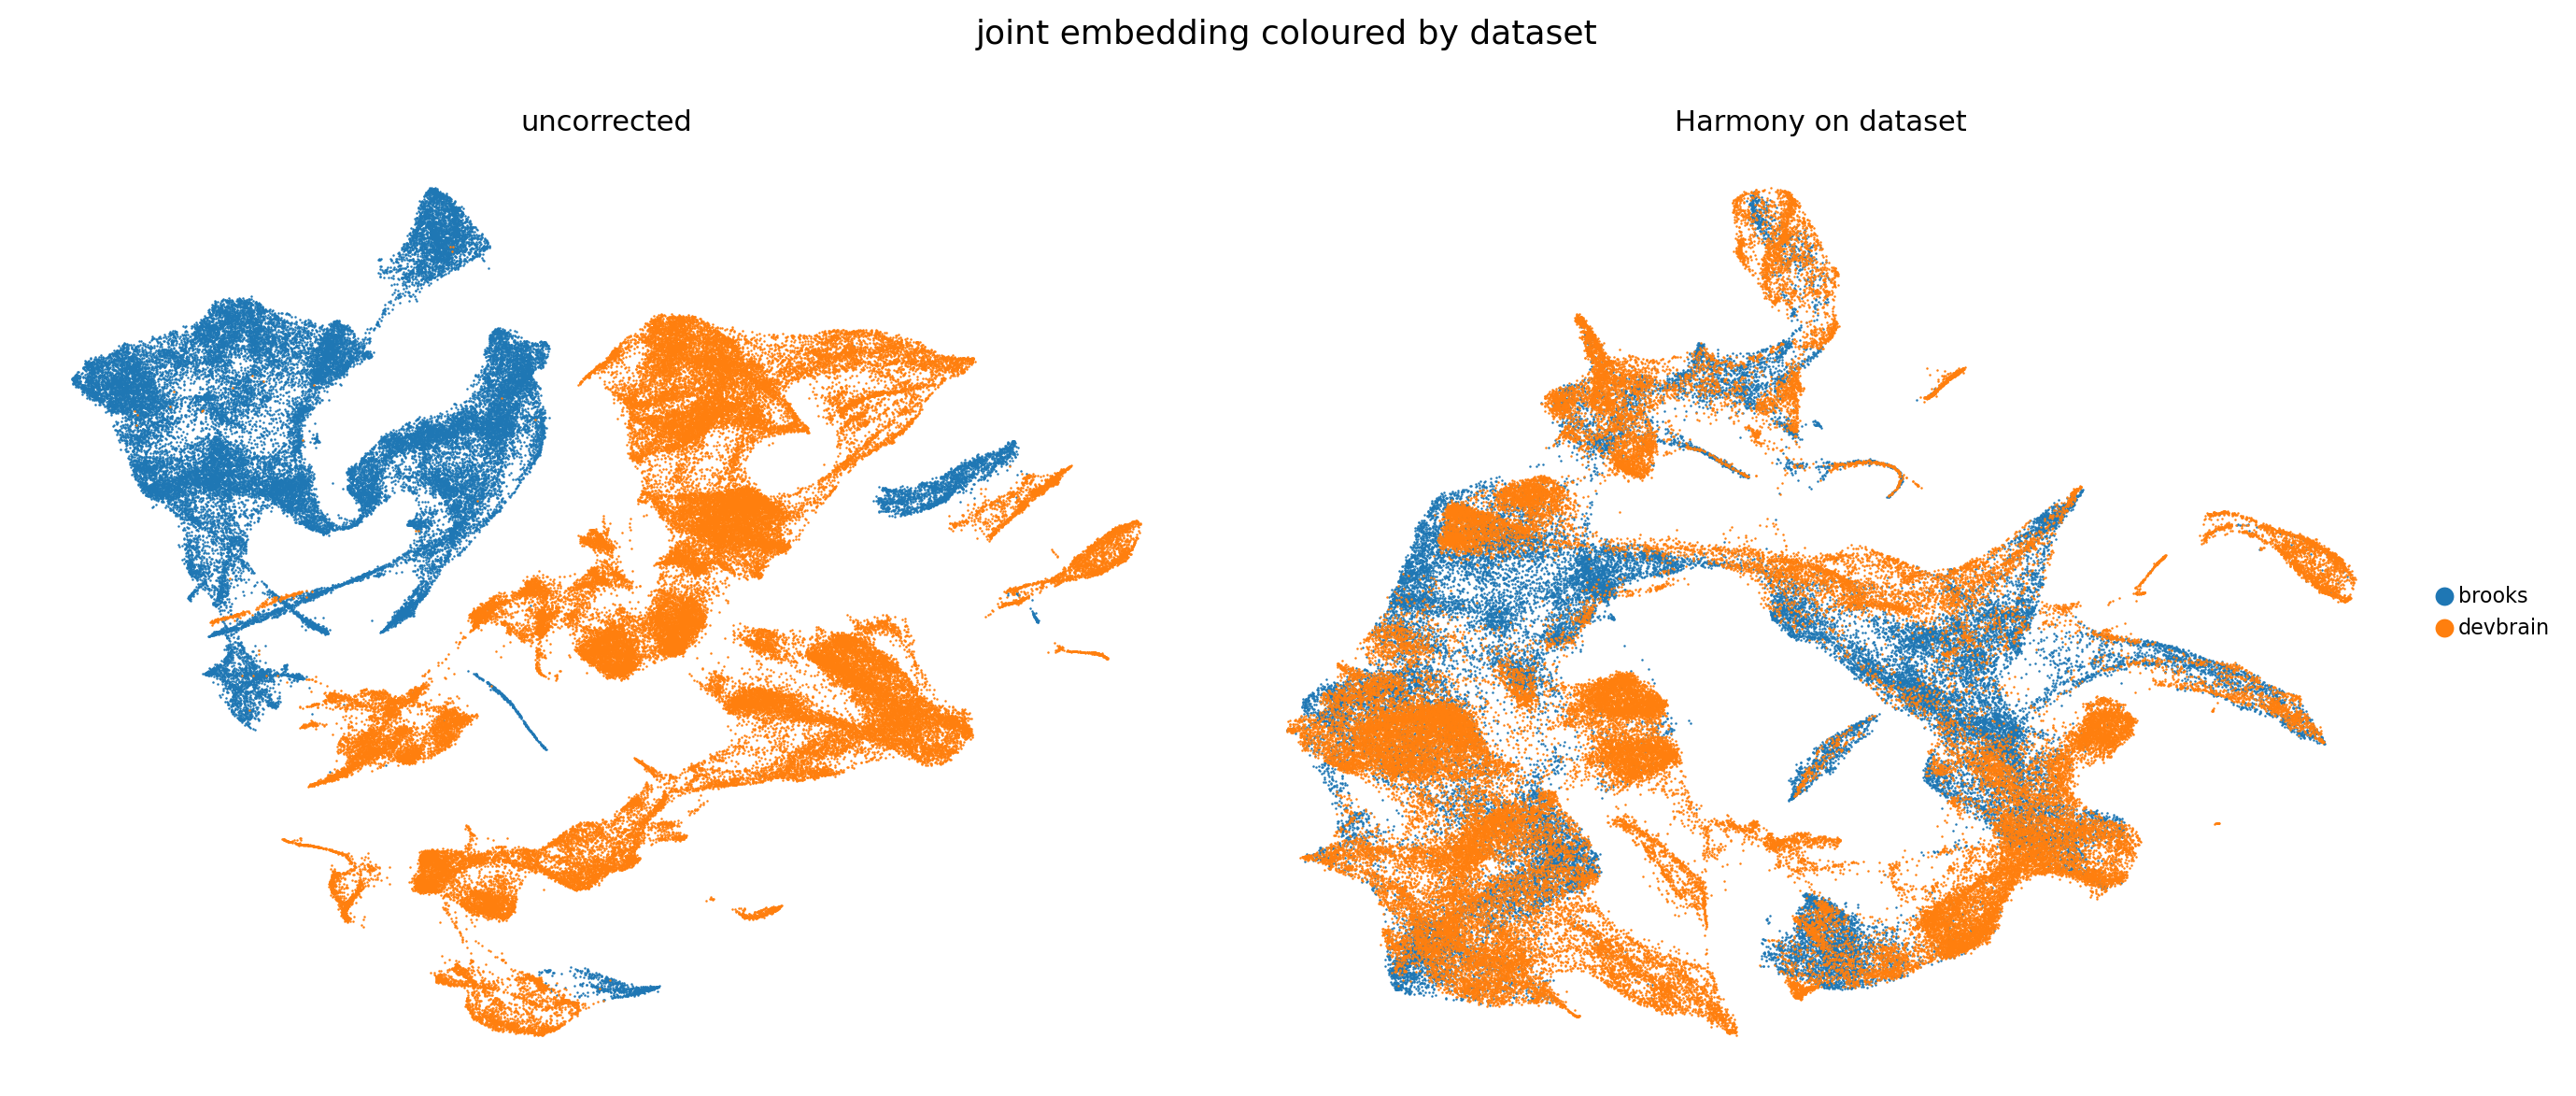

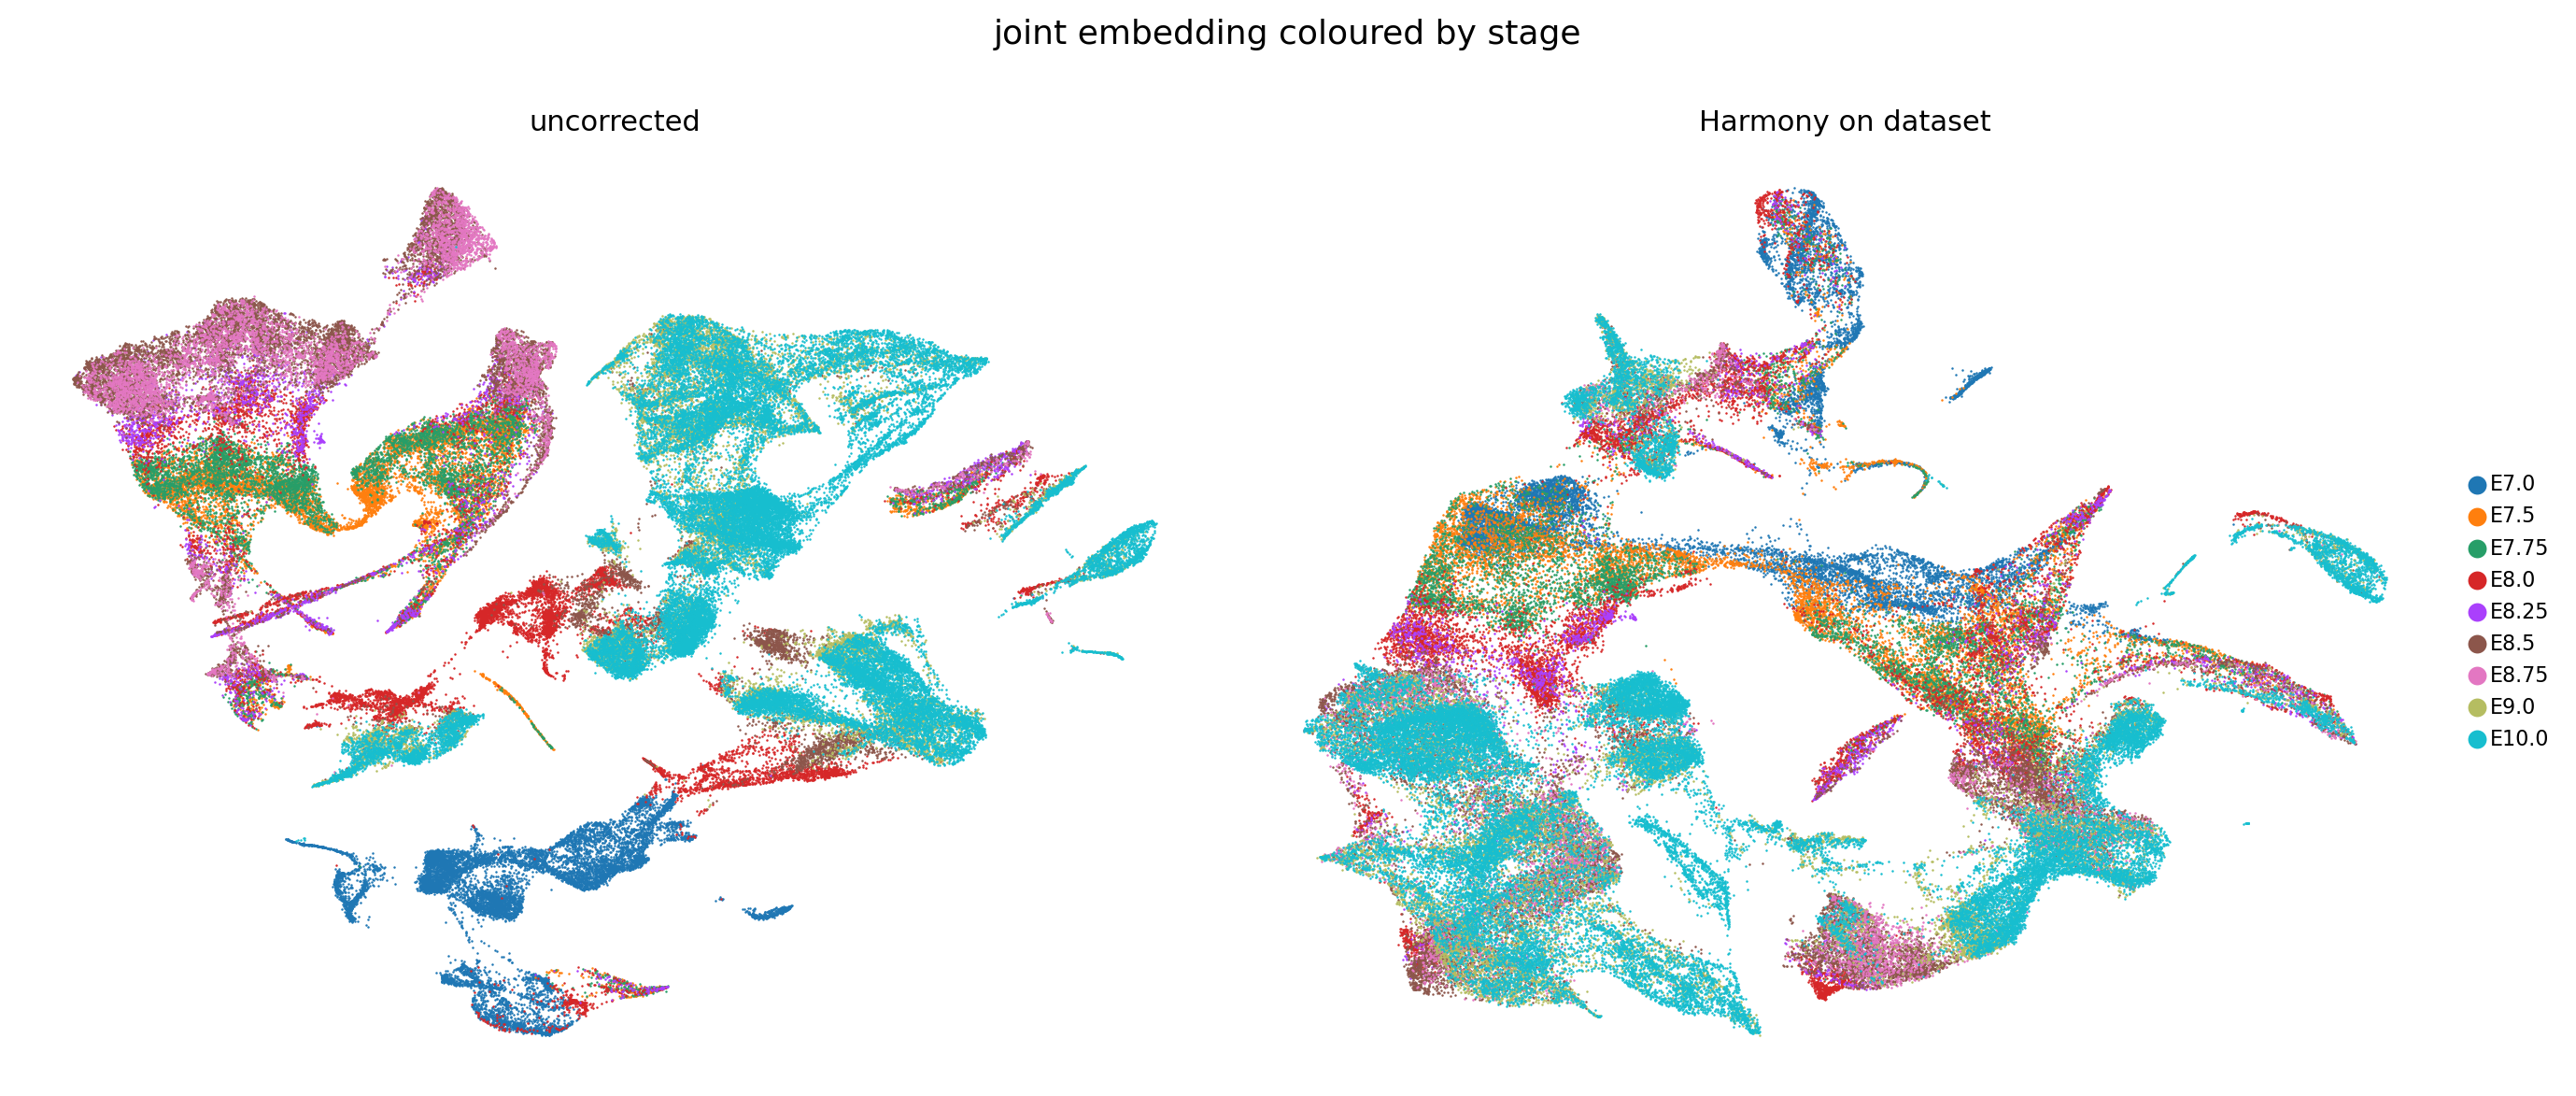

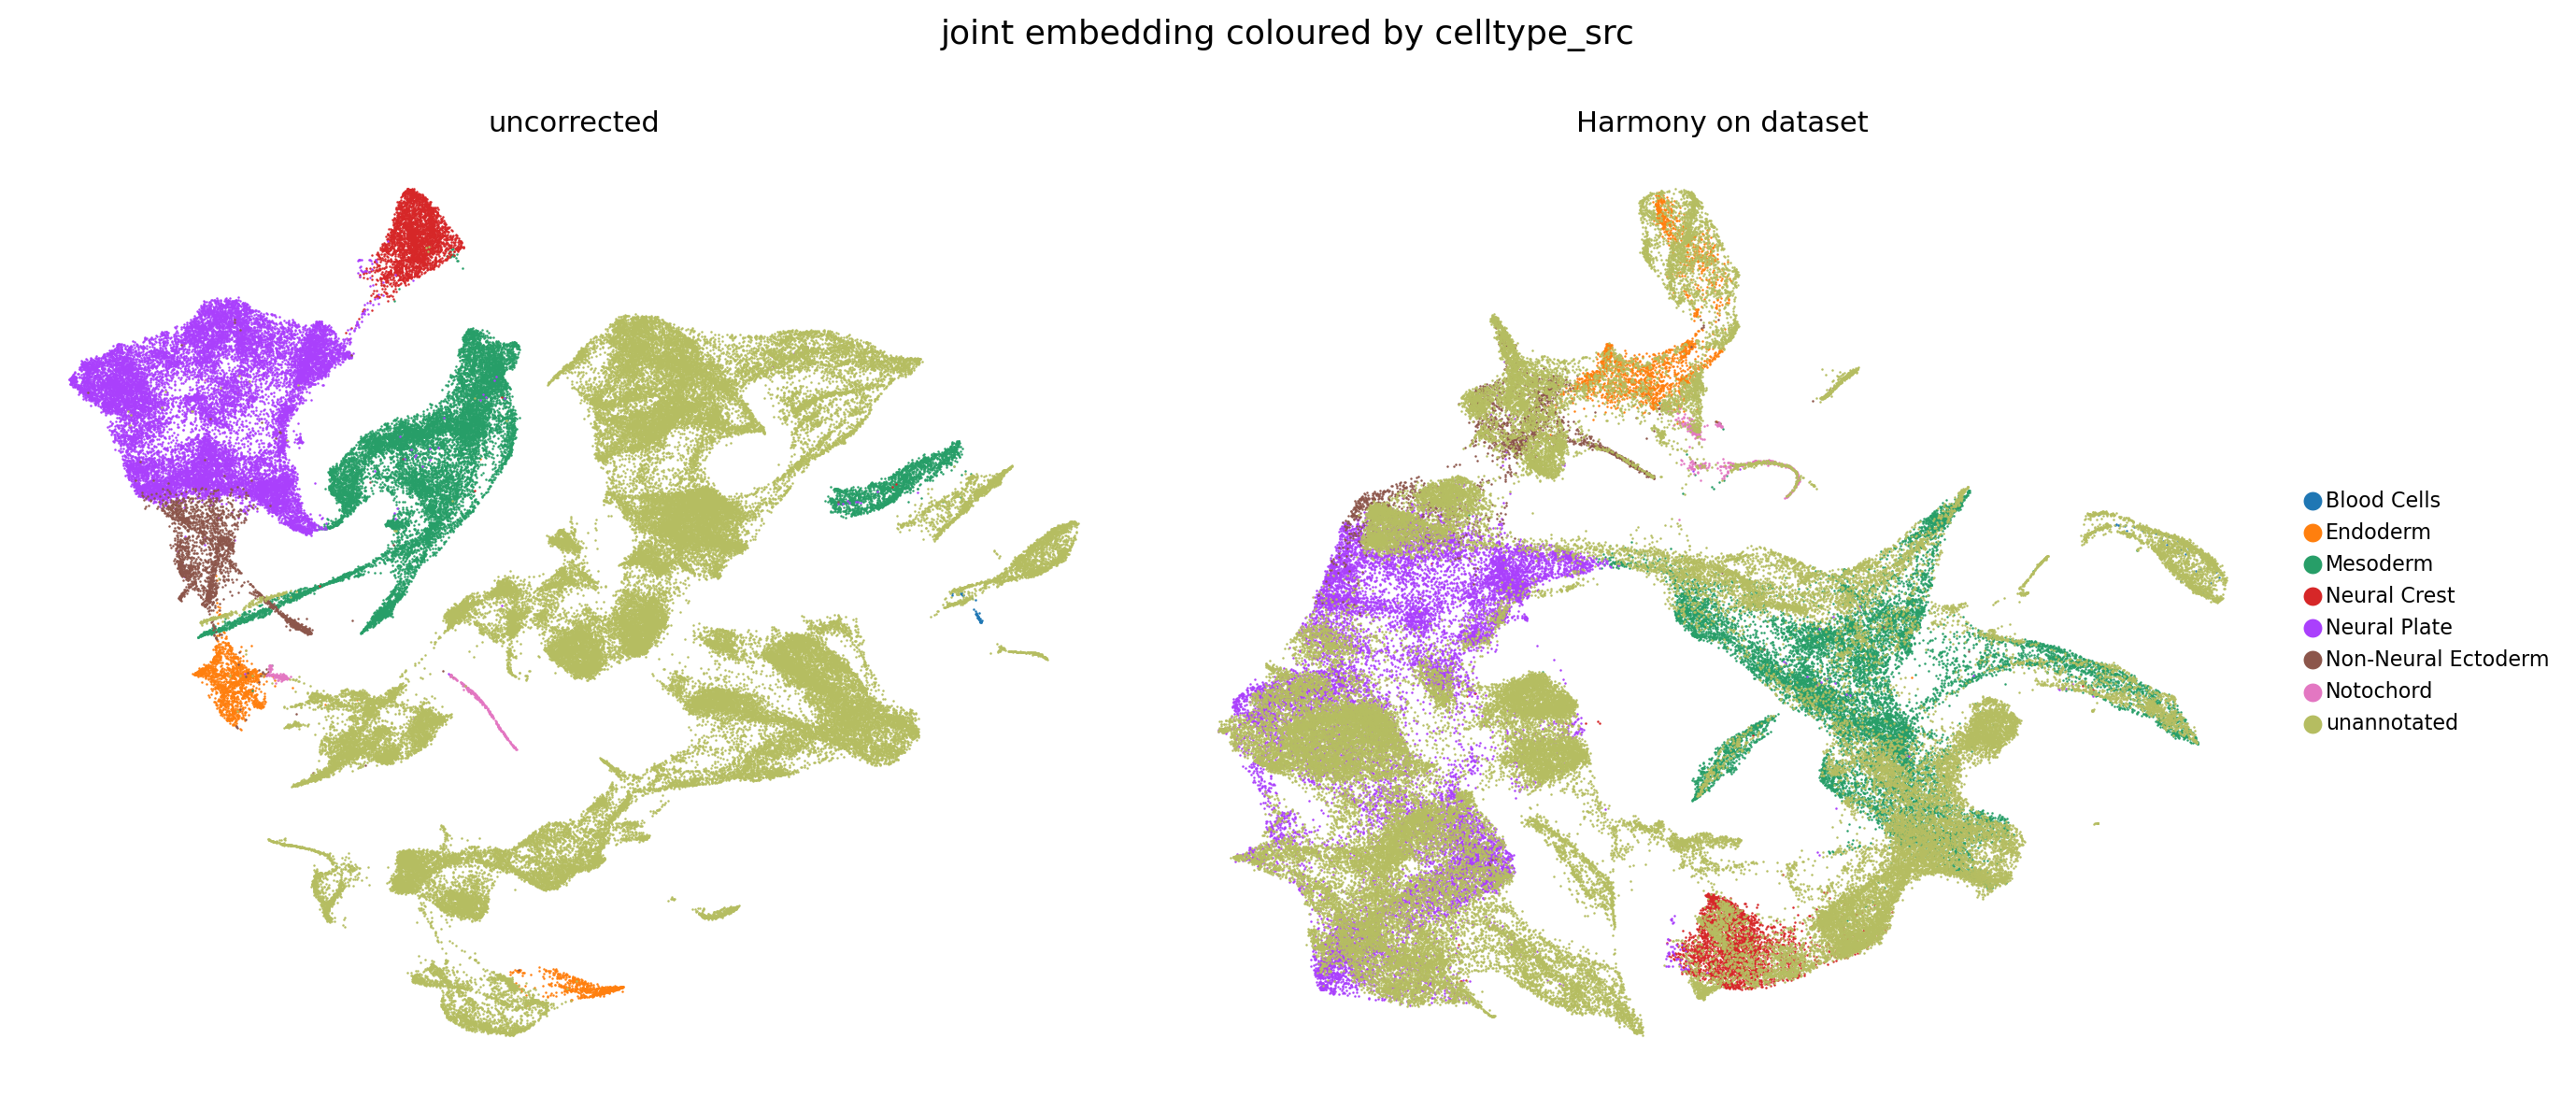

In [15]:
def scatter(ax, xy, groups, cats, colors, size=1.0, legend=False, title=""):
    for i, c in enumerate(cats):
        m = (groups == c).values
        ax.scatter(xy[m, 0], xy[m, 1], s=size, c=colors[i % len(colors)],
                   linewidths=0, rasterized=True, label=str(c))
    ax.set_title(title, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    if legend:
        ax.legend(markerscale=8, fontsize=8, frameon=False, loc="center left",
                  bbox_to_anchor=(1.01, 0.5))


PAL = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for key in ("dataset", "stage", "celltype_src"):
    cats = list(comb.obs[key].cat.categories)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, basis, lab in zip(axes, ["X_umap_pre", "X_umap_post"],
                              ["uncorrected", "Harmony on dataset"]):
        scatter(ax, comb.obsm[basis], comb.obs[key], cats, PAL, size=0.8,
                legend=(basis == "X_umap_post"), title=lab)
    fig.suptitle(f"joint embedding coloured by {key}", fontsize=13)
    fig.tight_layout()
    fig.savefig(fig_int + f"before_after_{key}.png", dpi=200, bbox_inches="tight")

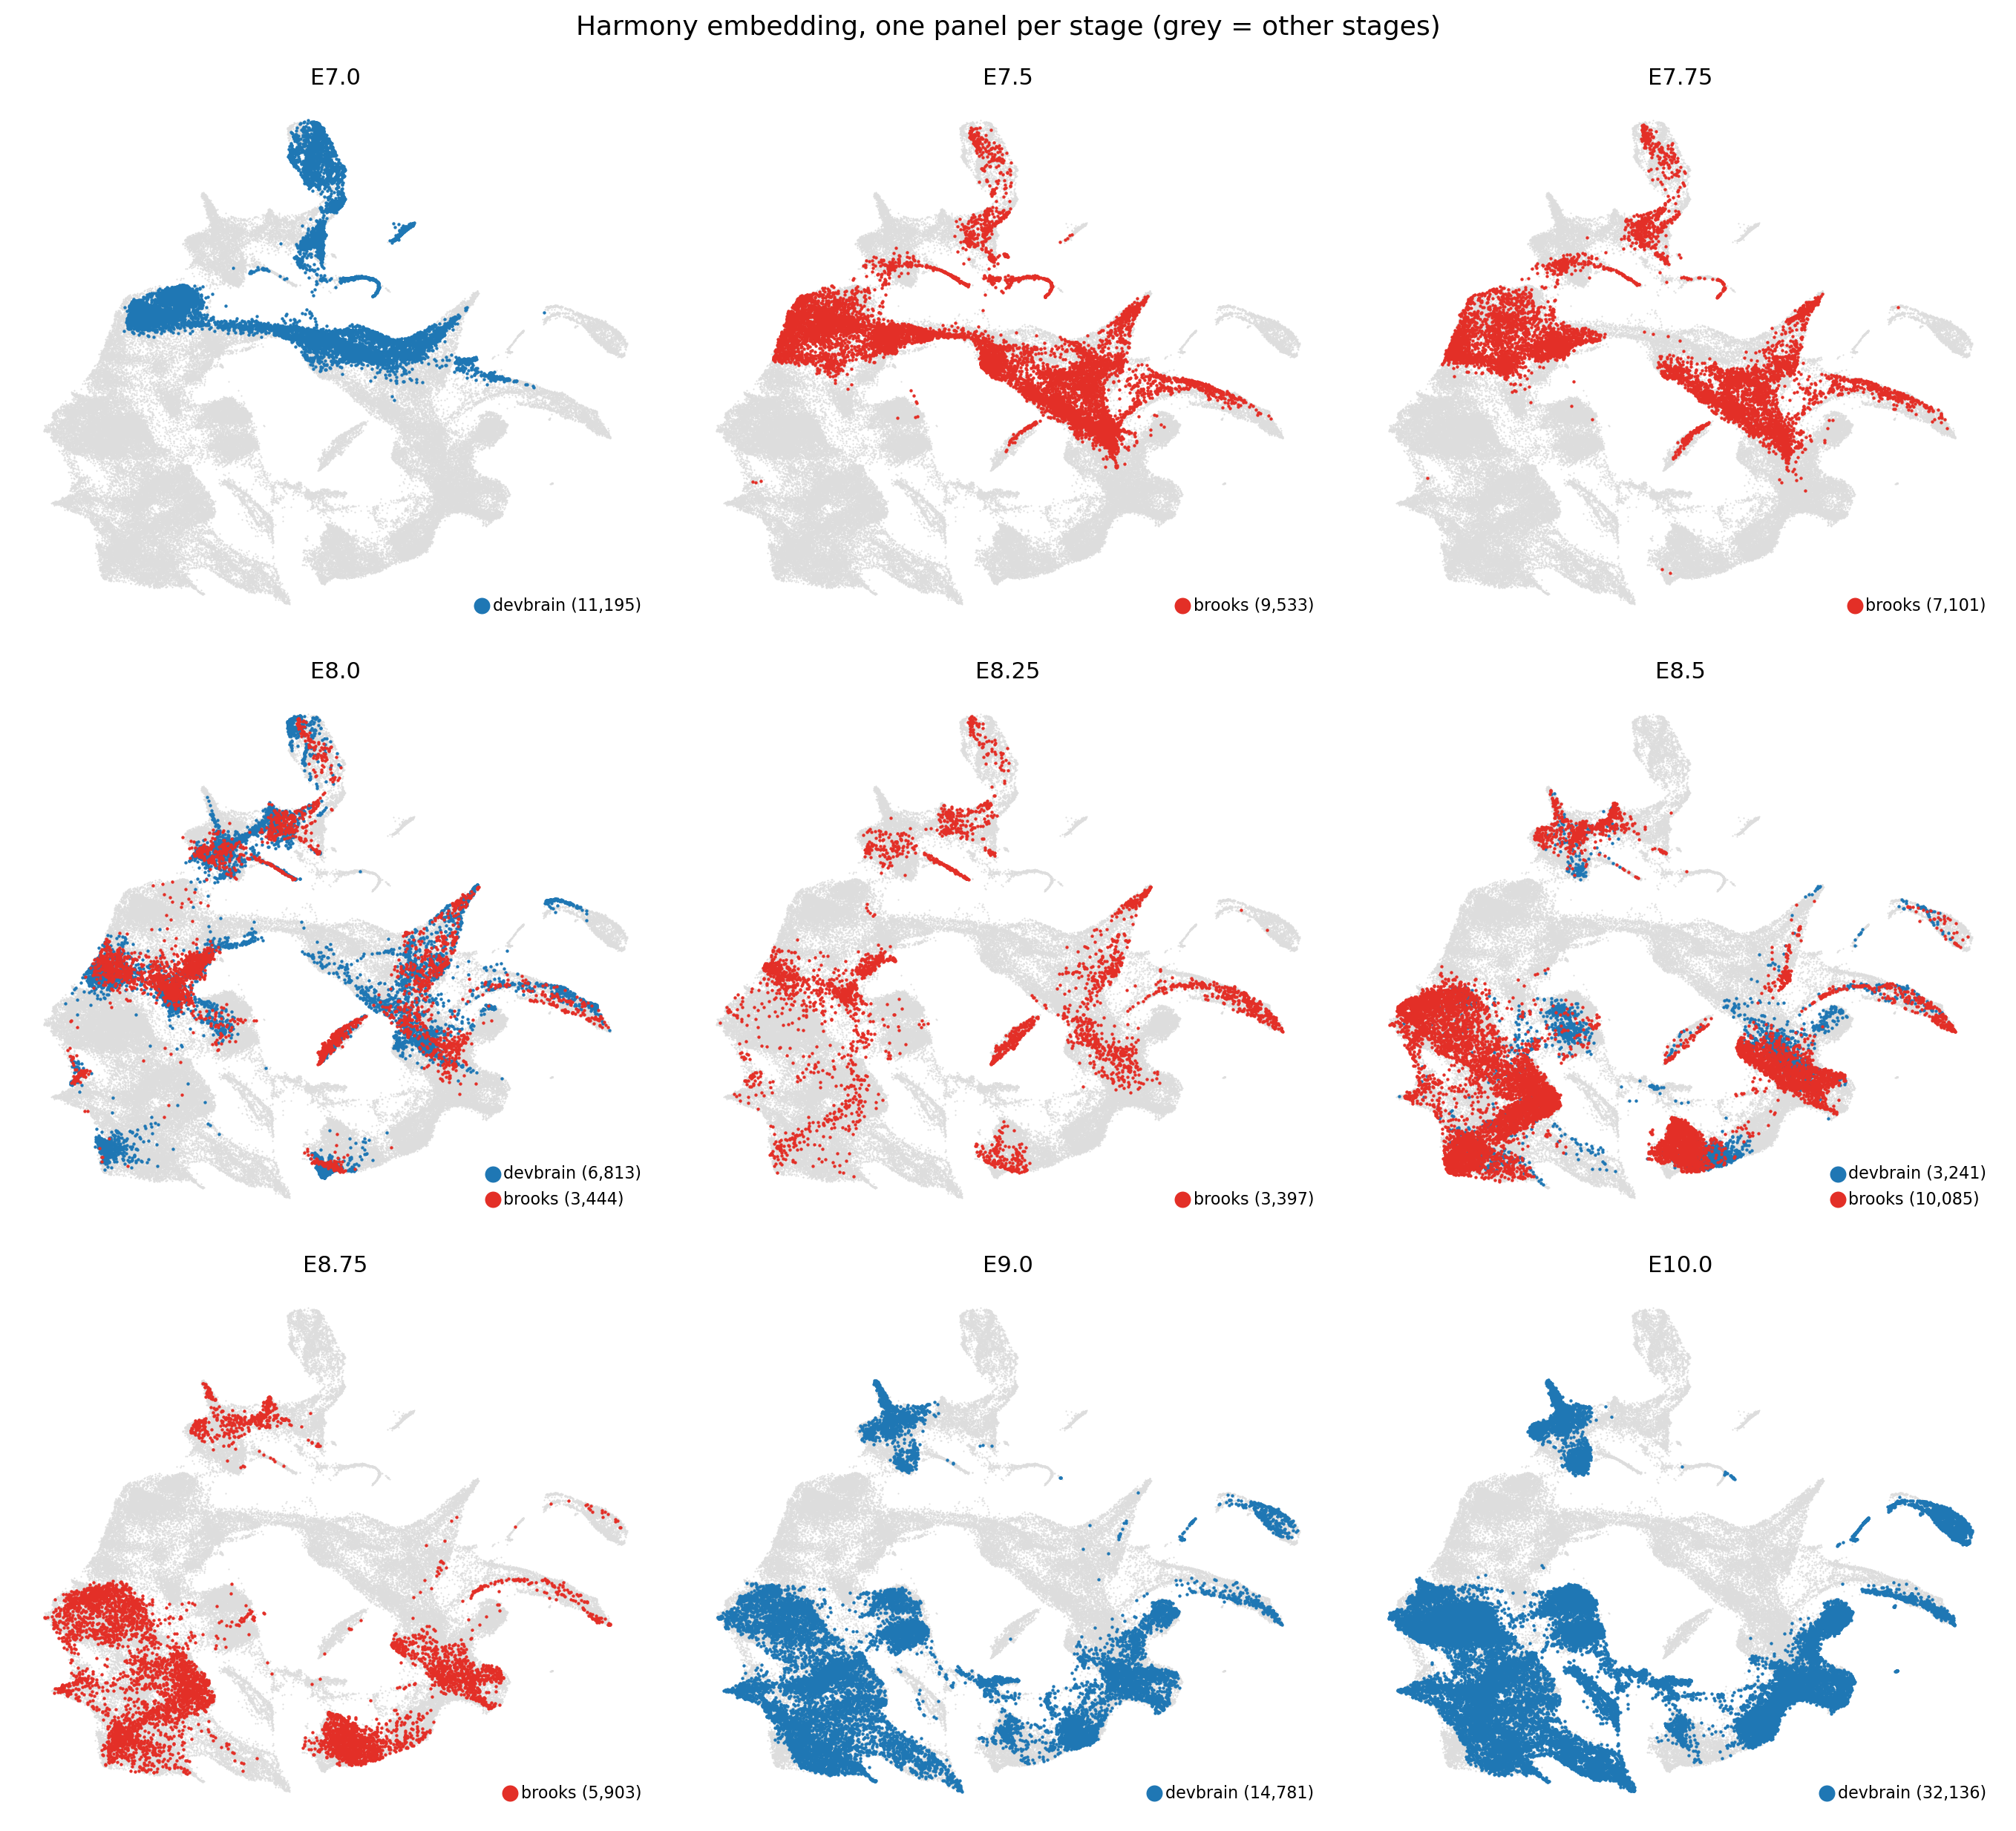

In [16]:
# one panel per stage on the corrected embedding, datasets coloured separately so
# you can see whether they coincide at the shared stages
stages = list(comb.obs["stage"].cat.categories)
ncols = 3
nrows = int(np.ceil(len(stages) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 4.2 * nrows))
axes = np.atleast_1d(axes).ravel()
xy = comb.obsm["X_umap_post"]
DS_COLOR = {"devbrain": "#1f77b4", "brooks": "#E32F27"}
for ax, stage in zip(axes, stages):
    m = (comb.obs["stage"] == stage).values
    ax.scatter(xy[~m, 0], xy[~m, 1], s=0.6, c=BG_GREY, linewidths=0, rasterized=True)
    for ds, col in DS_COLOR.items():
        mm = m & (comb.obs["dataset"] == ds).values
        if mm.sum():
            ax.scatter(xy[mm, 0], xy[mm, 1], s=2.5, c=col, linewidths=0,
                       rasterized=True, label=f"{ds} ({mm.sum():,})")
    ax.set_title(stage, fontsize=11)
    ax.legend(markerscale=5, fontsize=8, frameon=False, loc="lower right")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
for ax in axes[len(stages):]:
    ax.set_visible(False)
fig.suptitle("Harmony embedding, one panel per stage (grey = other stages)", fontsize=13)
fig.tight_layout()
fig.savefig(fig_int + "umap_facet_stage.png", dpi=200, bbox_inches="tight")

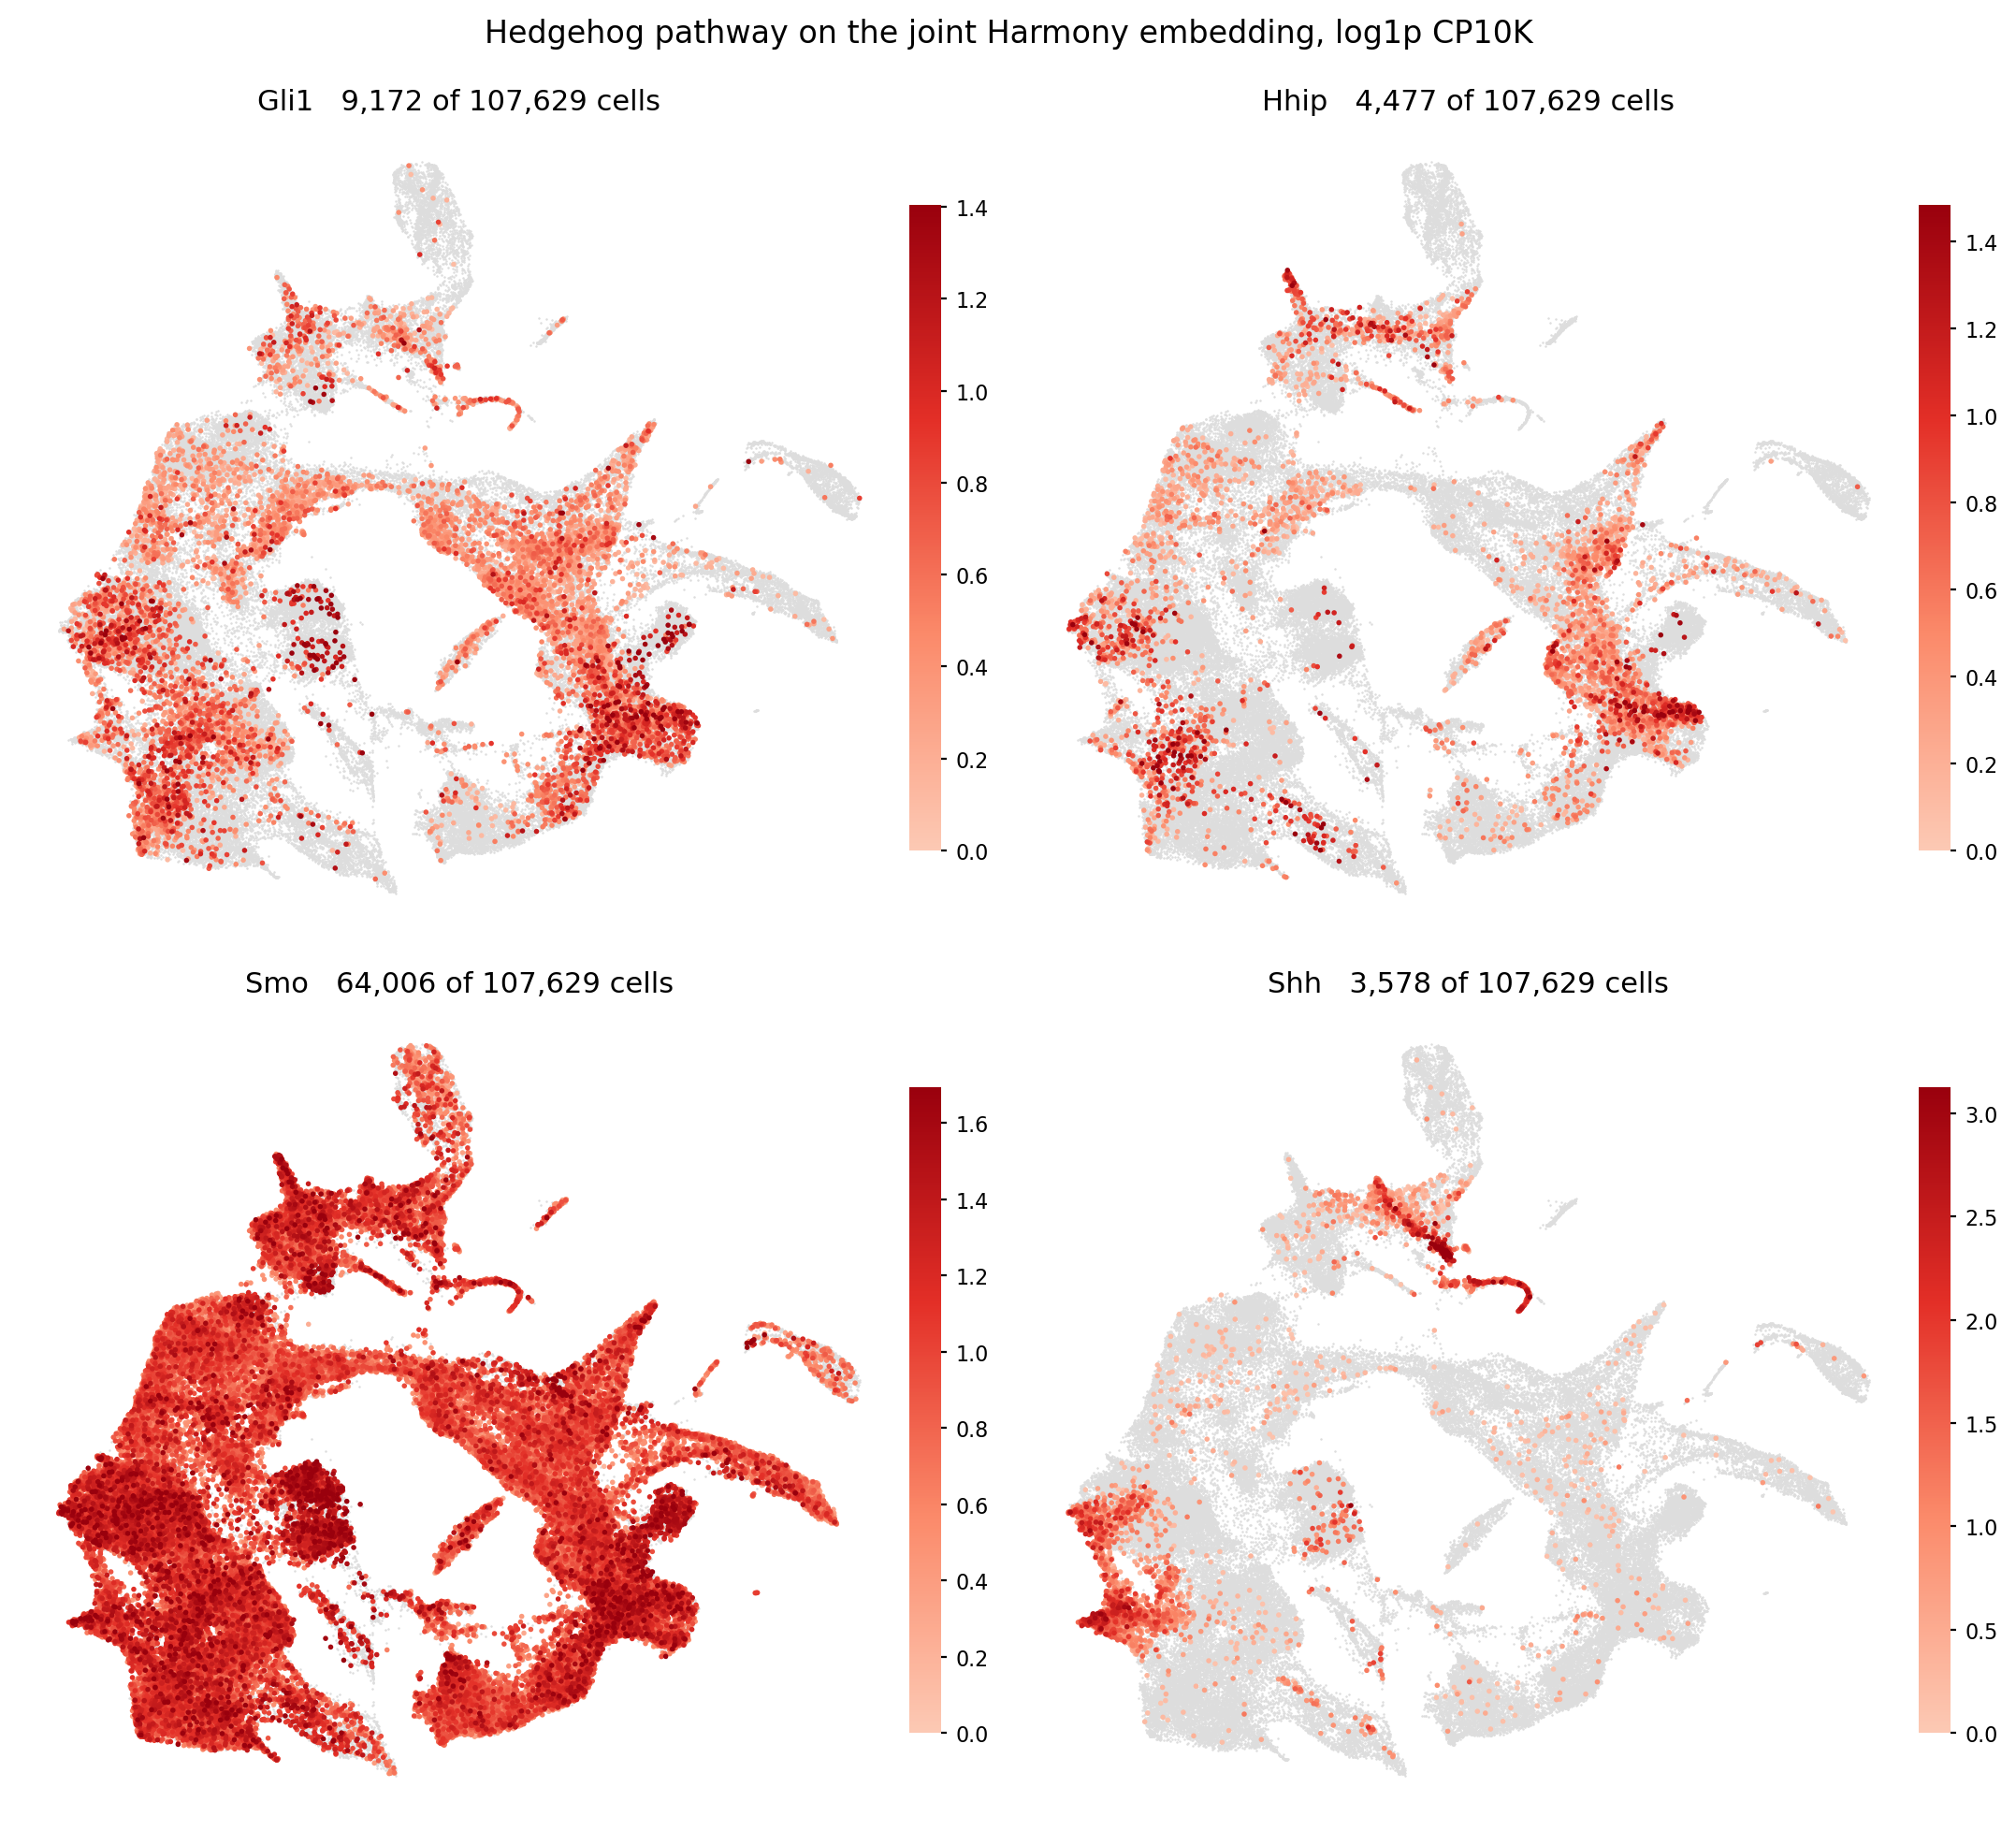

In [17]:
def feature_umap(adata, gene, ax=None, pct=99.0, bg_size=0.8, fg_size=4.0,
                 basis="X_umap_post"):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.5))
    xy = adata.obsm[basis]
    v = adata[:, gene].X
    v = np.asarray(v.todense()).ravel() if hasattr(v, "todense") else np.ravel(v)
    on = v > 0
    vmax = np.percentile(v[on], pct) if on.any() else 1.0
    ax.scatter(xy[~on, 0], xy[~on, 1], s=bg_size, c=BG_GREY, linewidths=0, rasterized=True)
    o = np.argsort(v[on])
    pts, vals = xy[on][o], v[on][o]
    sc_ = ax.scatter(pts[:, 0], pts[:, 1], s=fg_size, c=vals, cmap=EXPR_CMAP,
                     vmin=0, vmax=vmax, linewidths=0, rasterized=True)
    ax.set_title(f"{gene}   {on.sum():,} of {adata.n_obs:,} cells", fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    cb = plt.colorbar(sc_, ax=ax, fraction=0.035, pad=0.01)
    cb.ax.tick_params(labelsize=8, length=2)
    cb.outline.set_visible(False)
    return ax


genes = ["Gli1", "Hhip", "Smo", "Shh"]
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, g in zip(axes.ravel(), genes):
    feature_umap(comb, g, ax=ax)
fig.suptitle("Hedgehog pathway on the joint Harmony embedding, log1p CP10K", fontsize=12)
fig.tight_layout()
fig.savefig(fig_int + "umap_hedgehog_joint.png", dpi=200, bbox_inches="tight")

## Save

In [18]:
import resource
print(f"peak RSS: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.1f} GB")

out = base + "data/processed/devbrain_brooks_integrated.h5ad"
comb.write_h5ad(out, compression="gzip")
print(f"wrote {out}: {comb.n_obs} x {comb.n_vars}")
comb

peak RSS: 16.0 GB


wrote /project/imoskowitz/yubin/Trajectory_inference/data/processed/devbrain_brooks_integrated.h5ad: 107629 x 15200


AnnData object with n_obs × n_vars = 107629 × 15200
    obs: 'sample', 'age', 'tissue', 'leiden', 'dataset', 'stage', 'chip', 'batch_fine', 'celltype_src', 'stage_num', 'Sample ID', 'Batch', 'Cell Type', 'Neural Plate Annotation', 'background_cell', 'dataset_key', 'leiden_joint', 'component'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg', 'pca', 'pre', 'umap', 'post', 'leiden_joint'
    obsm: 'X_pca', 'X_umap', 'X_umap_pre', 'X_pca_harmony', 'X_umap_post'
    layers: 'counts'
    obsp: 'pre_distances', 'pre_connectivities', 'post_distances', 'post_connectivities'